# Lab 2 - SVM Classification with Non-Linear Dummy Data
## JS06 - Classification 2

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objective
Understand the kernel trick in SVM to classify non-linearly separable datasets, project data into higher dimensions using radial basis functions, and apply the RBF kernel in Scikit-Learn.

## Step 1 - Illustration of Non-Linear Data
### Step 1a - Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

sns.set_theme(style='whitegrid')
%matplotlib inline

### Step 1b - Recreate the Plotting Function

In [2]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # create a grid for model evaluation
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)
    
    # plot boundary and margins
    ax.contour(X_grid, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, edgecolors='k', facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Step 1c - Create Non-Linear Dummy Data
We generate concentric circular data using `make_circles`. A linear SVM fails to separate these two classes in 2D.

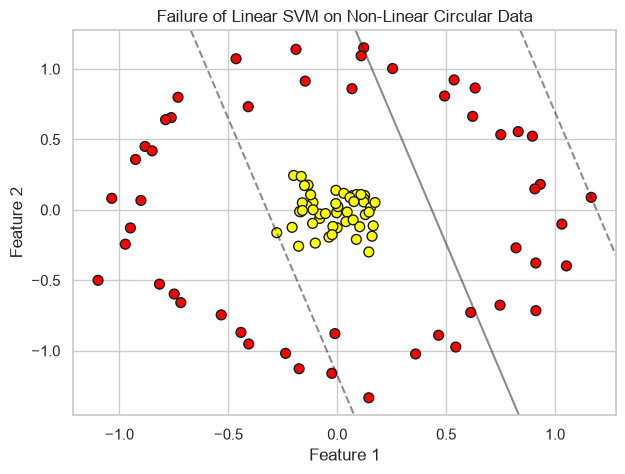

In [3]:
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1, random_state=0)

clf = SVC(kernel='linear').fit(X, y)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')
plot_svc_decision_function(clf, plot_support=False)
plt.title('Failure of Linear SVM on Non-Linear Circular Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

### Projecting into Higher Dimension (Radial Basis Function)
By computing a third dimension $r = \exp(-(X^2).\text{sum}(1))$, the concentric points become linearly separable in 3D space.

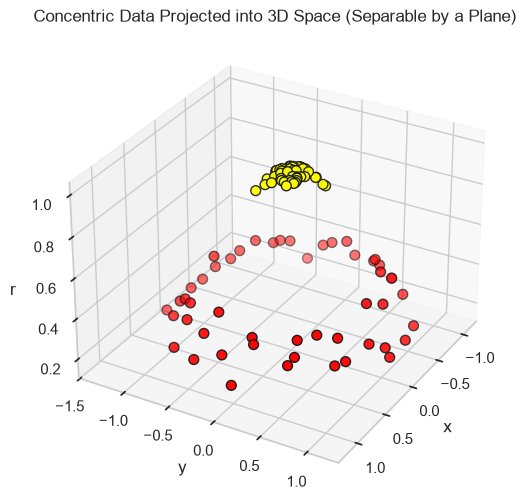

In [4]:
r = np.exp(-(X**2).sum(1))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')
ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn', edgecolors='k')
ax.view_init(elev=30, azim=30)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('r')
ax.set_title('Concentric Data Projected into 3D Space (Separable by a Plane)')
plt.show()

## Step 2 - Model Fitting with RBF Kernel
Instead of computing high-dimensional projections explicitly, the RBF (*Radial Basis Function*) kernel allows SVM to find non-linear decision boundaries efficiently via the kernel trick.

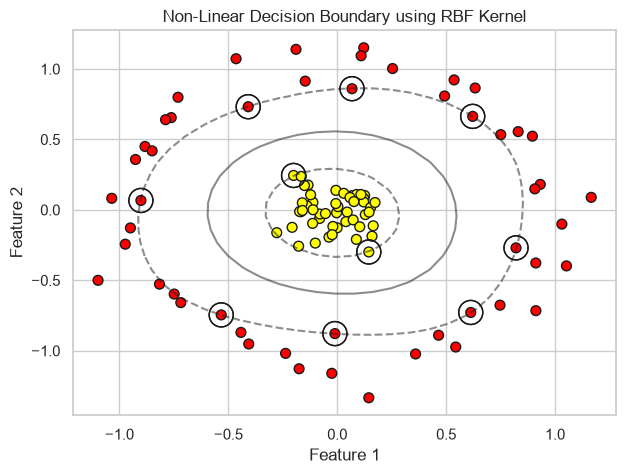

In [5]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, edgecolors='k', facecolors='none')
plt.title('Non-Linear Decision Boundary using RBF Kernel')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()